# 01 · Data quality and EDA

**Indoor Location Prediction Using Wi-Fi Signals** (Project 9) · Team T084

This notebook loads the UJIIndoorLoc data, cleans the training file, shows the key facts and
figures, and sets up the fair split that every later choice uses.

## 1. Load the data and look at three scans

**What:** load the training file and the test set (the UCI file validationData.csv), with the code
100 ("not heard") replaced by -110 dBm.

**Why:** as a number, 100 would look like the strongest signal of all.

**Result:** 19,937 training and 1,111 test scans, each with 520 WAP columns plus 9 others; the
three scans below hear only 17, 16 and 15 WAPs.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from indoorloc import config, data, pipeline, plots

plt.rcParams["figure.dpi"] = 150  # larger figures in the notebook
train_raw = data.load_csv(config.TRAIN_CSV)  # trainingData.csv
test = data.load_csv(config.TEST_CSV)  # validationData.csv, our test set
print(f"Training file: {len(train_raw):,} scans x {train_raw.shape[1]} columns")
print(f"Test set: {len(test):,} scans x {test.shape[1]} columns")
waps_heard = (train_raw[config.WAP_COLS] > config.FILL_VALUE).sum(axis=1)
columns = ["WAP001", "WAP090", "WAP172", "WAP248"] + config.TARGET_COLS + ["USERID", "PHONEID"]
train_raw.loc[:2, columns].assign(waps_heard=waps_heard).round(2)  # 4 of the 520 WAP columns

Training file: 19,937 scans x 529 columns
Test set: 1,111 scans x 529 columns


,WAP001,WAP090,WAP172,WAP248,BUILDINGID,FLOOR,LONGITUDE,LATITUDE,USERID,PHONEID,waps_heard
0,-110,-67,-54,-110,1,2,-7541.26,4864920.78,2,23,17
1,-110,-46,-62,-110,1,2,-7536.62,4864934.23,2,23,16
2,-110,-66,-61,-78,1,2,-7519.15,4864949.53,2,23,15


## 2. Clean the training file

**What:** drop training scans that hear no WAP, exact duplicate rows, and scans with any reading of
-30 dBm or stronger; the test set is never cleaned.

**Why:** such scans carry no location information, count twice, or hold physically implausible
readings.

**Result:** 1,218 scans are removed (76 + 634 + 508), which leaves 18,719 training scans.

In [2]:
train, cleaning = data.clean_training(train_raw)
cleaning

,step,scans_removed,scans_left
0,raw training file,0,19937
1,no WAP heard,76,19861
2,exact duplicate,634,19227
3,reading of -30 dBm or stronger,508,18719


## 3. Key facts: very sparse scans

**What:** the key numbers about the cleaned training scans and the test set
(results/metrics/eda_summary.json), and how many WAPs one scan hears.

**Why:** they explain the fill value (-110 dBm is weaker than every real reading) and why we keep
only the WAPs heard in training.

**Result:** 96.6% of the training readings are "not heard" (a scan hears 17.8 WAPs on average, a
test scan 16.5); real readings range from -104 to -31 dBm, and 55 WAPs are heard only in the test
set, so no model can learn them.

,value
training_scans,18719
test_scans,1111
waps_in_files,520
waps_heard_in_training,464
waps_heard_in_test,367
waps_heard_only_in_test,55
share_of_readings_not_heard_training,0.9657
mean_waps_per_scan_training,17.82
mean_waps_per_scan_test,16.48
strongest_reading_training_dbm,-31


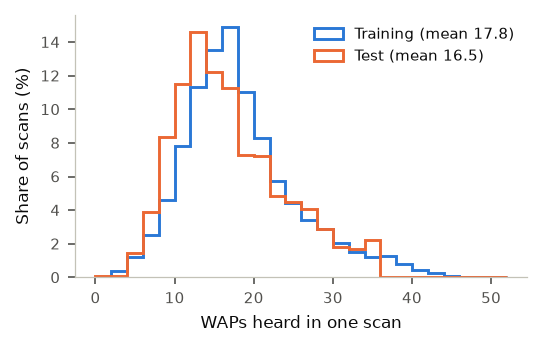

In [3]:
summary = json.loads((config.RESULTS_DIR / "metrics" / "eda_summary.json").read_text())
fig = plots.waps_per_scan(train, test)
pd.Series(summary).to_frame("value")

## 4. Where the scans were taken

**What:** training positions colored by building, test positions as black crosses.

**Why:** to see the campus and check that the test set covers the same buildings.

**Result:** the three buildings lie side by side (the training scans span 390.5 m x 270.9 m), and
the test scans fall on the same buildings; positions are Web-Mercator meters, and one such meter is
about 0.77 m on the ground.

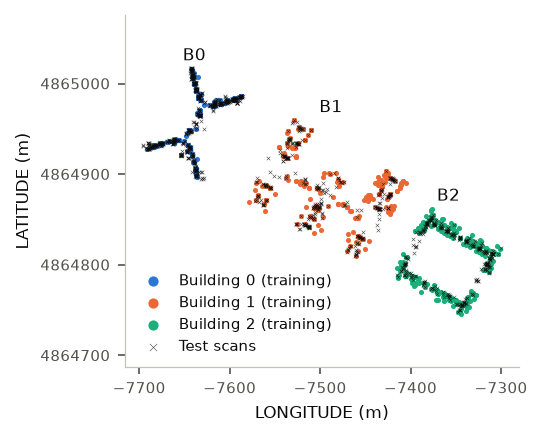

In [4]:
fig = plots.campus_map(train, test)

## 5. Scans per building and floor

**What:** the share of scans on each of the 13 floors (B0-F0 = building 0, floor 0).

**Why:** the models must learn every floor, and the test set may have a different mix.

**Result:** every floor has training scans, B2-F4 the fewest; the test set has a different mix,
with many more scans in building 0.

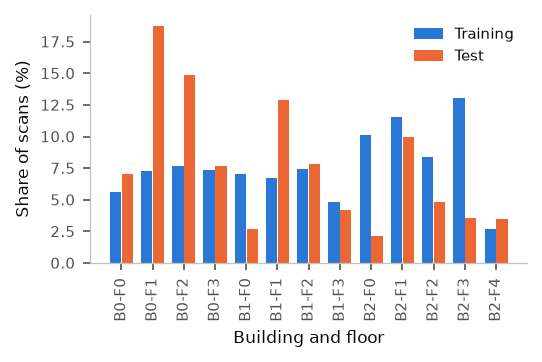

In [5]:
fig = plots.scans_per_floor(train, test)

## 6. Users, phones and why the test set is hard

**What:** who recorded the training scans and with which phone; users who shared a phone form one
user-device group.

**Why:** the test set comes mostly from new phones, so a fair check must hold out whole groups.

**Result:** users 1, 9 and 16 shared phone 14, so the 18 users form 16 groups; and, as the key
facts in section 3 show, the test set was recorded about three months later, with 64.3% of its
scans from phones not seen in training (9 of its 11 phones).

In [6]:
groups = data.user_device_groups(train)  # one group per user; users who shared a phone are merged
pairs = train[["PHONEID", "USERID"]].drop_duplicates()
shared = pairs[pairs.duplicated("PHONEID", keep=False)]  # phones used by more than one user
print(f"Users {sorted(shared['USERID'].tolist())} all used phone {shared['PHONEID'].iloc[0]}")
print(f"{train['USERID'].nunique()} users -> {len(set(groups))} user-device groups")

Users [1, 9, 16] all used phone 14
18 users -> 16 user-device groups


## 7. A fair split, and a check that it matters

**What:** the feature set, the settings and the final model are chosen with 5-fold user-group
cross-validation (CV) on the training data, where each fold holds out whole user-device groups;
the test set is used only once, at the end.

**Why:** random CV mixes scans of the same people and phones into both parts, so it is tested on
scans very like the ones it learned from.

**Result:** for the Baseline RF, random CV promises a mean 2D error (straight-line distance between
predicted and true position) of 3.67 m, but the test set gives 12.52 m; user-group CV (15.87 m) is
stricter than the test set, so it errs on the safe side.

In [7]:
folds = pipeline.make_folds(train, "user")
for number, (_, held_out) in enumerate(folds, start=1):
    users = sorted(train["USERID"].iloc[held_out].unique().tolist())
    print(f"Fold {number} holds out {len(held_out):,} scans of users {users}")
pd.read_csv(config.RESULTS_DIR / "metrics" / "cv_check.csv")

Fold 1 holds out 4,811 scans of users [1, 9, 16]
Fold 2 holds out 4,514 scans of users [11]
Fold 3 holds out 3,194 scans of users [4, 5, 8, 13, 14]
Fold 4 holds out 3,024 scans of users [7, 12, 15, 17]
Fold 5 holds out 3,176 scans of users [2, 3, 6, 10, 18]


,evaluation,building_acc,floor_acc,mean_2d
0,random CV,1.0000,0.9987,3.6655
1,user-group CV,0.9965,0.7799,15.8709
2,test set,0.9982,0.9118,12.5188


## Summary

- Cleaning (training file only) keeps 18,719 of 19,937 scans; the 1,111 test scans are used as
  published.
- Scans are very sparse (96.6% of readings "not heard"): "not heard" becomes -110 dBm, and only the
  464 WAPs heard in training are kept.
- The test set comes months later and mostly from new phones, so the feature set, the settings and
  the final model are chosen with user-group CV; for the Baseline RF, random CV would promise
  3.67 m where the test set gives 12.52 m.